Problem → Base model → LoRA → Data → Baseline → Training → Evaluation → Calibration → Real decision → Hugging Face → Reuse → Agent architecture.

“Today I'm going to show you something slightly different from a traditional LLM chatbot. Instead of asking the model to generate a long answer, I'm going to train a model specifically to make structured decisions.”

Then point to the three decision types:
- Choice — which option should be selected?
- Noul — yes/no decision
- Score — which level is appropriate?
Then give your audience the example:
“Imagine a customer says: I was charged twice for my invoice and I need the duplicate refunded today. We want an AI system that can immediately determine which team should handle it, whether a refund is requested, and how urgent it is.”

That immediately gives them a reason to care.

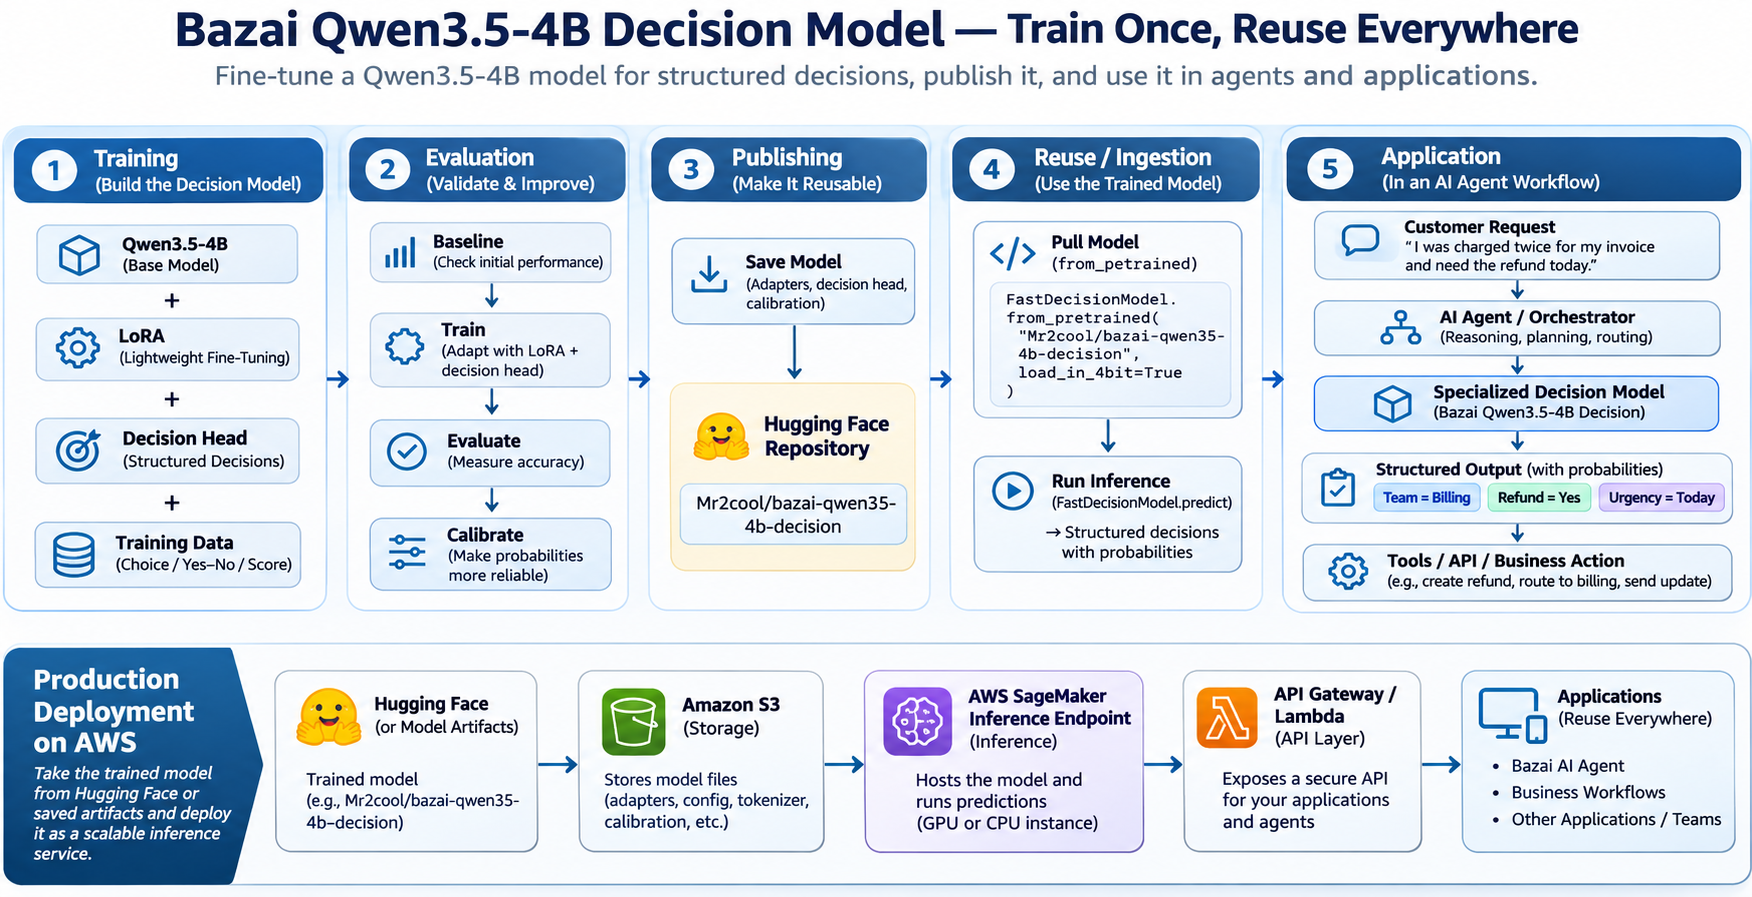

So what did we actually build? We started with Qwen3.5-4B, adapted it with LoRA, trained a decision head, evaluated it, calibrated its confidence, tested it on unseen data, and then published the trained model. The important part isn't just that we fine-tuned an LLM. We've created a reusable decision component that can be called by an application or an AI agent. And because it's specialized, the output is structured, predictable, and directly usable by software

Problem → Base model → LoRA → Data → Baseline → Training → Evaluation → Calibration → Real decision → Hugging Face → Reuse → Agent architecture.

To run this, press "*Runtime*" and press "*Run all*" on a **free** Tesla T4 Google Colab instance!
<div class="align-center">
<a href="https://unsloth.ai/"><img src="https://github.com/unslothai/unsloth/raw/main/images/unsloth%20new%20logo.png" width="115"></a>
<a href="https://discord.gg/unsloth"><img src="https://github.com/unslothai/unsloth/raw/main/images/Discord button.png" width="145"></a>
<a href="https://unsloth.ai/docs/"><img src="https://github.com/unslothai/unsloth/blob/main/images/documentation%20green%20button.png?raw=true" width="125"></a> Join Discord if you need help + ⭐ <i>Star us on <a href="https://github.com/unslothai/unsloth">Github</a> </i> ⭐
</div>

To install Unsloth on your local device, follow [our guide](https://unsloth.ai/docs/get-started/install). This notebook is licensed [LGPL-3.0](https://github.com/unslothai/notebooks?tab=LGPL-3.0-1-ov-file#readme).

You will learn how to do [data prep](#Data), how to [train](#Train), how to [run the model](#Inference), & how to save it

### News

Introducing **[Unsloth Desktop](https://unsloth.ai/docs/desktop)**, the first desktop app to run and train models. Free and open-source for macOS, Windows and Linux. [GitHub](https://github.com/unslothai/unsloth) • [Download](https://unsloth.ai/download)

<p>
<a href="https://unsloth.ai/docs/desktop"><img src="https://raw.githubusercontent.com/unslothai/notebooks/refs/heads/main/assets/unsloth-qwen3-8.png" width="350" alt="Introducing Unsloth Desktop"></a>
</p>

Train MoEs - DeepSeek, GLM, Qwen and gpt-oss 12x faster with 35% less VRAM. [Blog](https://unsloth.ai/docs/new/faster-moe)

Ultra Long-Context Reinforcement Learning is here with 7x more context windows! [Blog](https://unsloth.ai/docs/new/grpo-long-context)

New in Reinforcement Learning: [FP8 RL](https://unsloth.ai/docs/new/fp8-reinforcement-learning) • [Vision RL](https://unsloth.ai/docs/new/vision-reinforcement-learning-vlm-rl) • [Standby](https://unsloth.ai/docs/basics/memory-efficient-rl) • [gpt-oss RL](https://unsloth.ai/docs/new/gpt-oss-reinforcement-learning)

Visit our docs for all our [model uploads](https://unsloth.ai/docs/get-started/unsloth-model-catalog) and [notebooks](https://unsloth.ai/docs/get-started/unsloth-notebooks).

### Installation

In [ ]:
%%capture
import os, importlib.util
!pip install --upgrade -qqq uv
if importlib.util.find_spec("torch") is None or "COLAB_" in "".join(os.environ.keys()):
    try: import numpy, PIL; _numpy = f"numpy=={numpy.__version__}"; _pil = f"pillow=={PIL.__version__}"
    except: _numpy = "numpy"; _pil = "pillow"
    !uv pip install -qqq \
        "torch==2.8.0" "triton>=3.3.0" {_numpy} {_pil} torchvision "torchaudio==2.8.0" bitsandbytes xformers==0.0.32.post2 \
        "unsloth_zoo[base] @ git+https://github.com/unslothai/unsloth-zoo" \
        "unsloth[base] @ git+https://github.com/unslothai/unsloth"
    !uv pip install -qqq --no-deps "torchcodec==0.7.0"
elif importlib.util.find_spec("unsloth") is None:
    !uv pip install -qqq unsloth
!uv pip install --upgrade --no-deps "tokenizers>=0.22.0,<=0.23.0" trl==0.22.2 unsloth unsloth_zoo
!uv pip install transformers==5.2.0
!unsloth install-kernels
!uv pip install --no-deps --upgrade "torchao>=0.16.0"

### Unsloth

A decision model doesn't write text. It reads an input, looks at the options you give it, and picks one with a probability. `FastDecisionModel` turns an LLM into one: it adds a small head that reads every question about an input in one pass and scores each option.

Change `model_name` to `unsloth/Llama-3.2-3B-Instruct` or `unsloth/gemma-4-E4B-it` to try other models.

In [ ]:
from unsloth import FastDecisionModel, DecisionTrainer, is_bfloat16_supported
import torch

model, tokenizer = FastDecisionModel.from_pretrained(
    model_name = "unsloth/Qwen3.5-4B",
    max_seq_length = 2048, # Longest input. Long inputs keep the question and options.
    load_in_4bit = True, # 4 bit quantization to reduce memory
)

==((====))==  Unsloth 2026.11.6: Fast Qwen3_5 patching. Transformers: 5.2.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.8.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.4.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.32.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

We now add LoRA adapters so we only need to update a small amount of parameters! The new decision head always trains.

In [ ]:
model = FastDecisionModel.get_peft_model(
    model,
    r = 16, # Choose any number > 0 ! Suggested 8, 16, 32, 64, 128
    lora_alpha = 16,
    lora_dropout = 0, # Supports any, but = 0 is optimized
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for very long context
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We use the [typed-decisions](https://huggingface.co/datasets/LocalLLaMA/typed-decisions) dataset. Each row has a `state` (the input), the `questions` to decide about it, and the `gold` answers. There are three kinds of questions:

* `choice`: pick one option, like which team should handle a ticket.
* `noul`: yes or no.
* `score`: pick a level, like how urgent something is.

Let's see how row 0 looks like!

In [ ]:
from datasets import load_dataset
import json

dataset = load_dataset("LocalLLaMA/typed-decisions", "all", split = "train")
print(dataset[0]["state"][:500])
print(json.dumps(json.loads(dataset[0]["questions"]), indent = 2)[:1000])
print(dataset[0]["gold"])

README.md:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

all/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  599kB            

all/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

all/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  222kB            

all/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

{"agent": {"autonomy": "checkpointed", "model": "internal-agent-v4"}, "constraints": ["Do not touch customer data outside the named accounts"], "task": "Delete personal data for the accounts in the erasure queue.", "trace_summary": {"constraint_violations": 0, "duration_s": 128.5, "irreversible_actions": 0, "steps": 7, "tool_errors": 1}}
{
  "action": {
    "criteria": {
      "continue": "Let the agent proceed without interruption.",
      "human_review": "Queue this trace for a human to review.",
      "observe": "Keep running, but flag the trace for later sampling.",
      "stop": "Halt the agent now."
    },
    "instructions": "What should the observability system do with this trace?",
    "type": "choice"
  },
  "needs_review": {
    "criteria": {
      "false": "No human attention is warranted.",
      "true": "A human should inspect this run."
    },
    "instructions": "This trace requires human review.",
    "type": "noul"
  },
  "outcome": {
    "criteria": {
      "failure"

`build_dataset` turns every row into one example holding all of its questions, and tells you how many decisions it skipped and why. To use your own data, give it a list of rows with the same `state`, `questions` and `gold` fields.

`split_holdout` keeps some rows out of training (80 rows, 400 decisions here), so we can check accuracy and calibrate the model later.

In [ ]:
items, report = FastDecisionModel.build_dataset(dataset, tokenizer, model)
print(f"Skipped {report['skipped']} of {report['total']} decisions")

train_items, eval_items = FastDecisionModel.split_holdout(items, seed = 3407)
print(f"{len(train_items)} training rows, {len(eval_items)} held out")

Skipped 0 of 6000 decisions
1120 training rows, 80 held out


Let's check accuracy before training. The head is new, so it's about the same as guessing (about 30% accuracy in our runs).

In [ ]:
FastDecisionModel.evaluate(model, tokenizer, eval_items)

{'accuracy': 0.3025,
 'ece': 0.06227223098278045,
 'loss': 1.2141607894003392,
 'record_accuracy': 0.0}

<a name="Train"></a>
### Train the model
Now let's train our model. We do 60 steps (about 1.7 epochs) to speed things up, which reached 75% to 78% test accuracy in our runs and took about 2 hours on a free T4 GPU (12 minutes on an RTX PRO 6000). The T4 has no bfloat16 and Qwen3.5 gives NaNs in pure float16, so Unsloth trains it in float32 there, which is why the T4 is slow. For the full run, set `num_train_epochs = 2` and remove `max_steps`: that is 70 steps here, and it reached 78% test accuracy in 25 minutes on an A100.

In [ ]:
from transformers import TrainingArguments

trainer = DecisionTrainer(
    model = model,
    processing_class = tokenizer,
    train_dataset = train_items,
    eval_dataset = eval_items,
    args = TrainingArguments(
        per_device_train_batch_size = 8,
        gradient_accumulation_steps = 4, # Use GA to mimic batch size!
        warmup_steps = 10,
        # num_train_epochs = 2, # Set this for 1 full training run.
        max_steps = 60,
        learning_rate = 2e-4,
        lr_scheduler_type = "cosine",
        weight_decay = 0.01,
        bf16 = is_bfloat16_supported(),
        fp16 = not is_bfloat16_supported(),
        eval_strategy = "epoch",
        logging_steps = 10,
        output_dir = "outputs",
        report_to = "none", # Use TrackIO/WandB etc
        seed = 3407,
    ),
)

Unsloth: Qwen3.5 overflows under float16 autocast, so Clef trains without autocast, keeping float32 activations.


In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = Tesla T4. Max memory = 14.563 GB.
8.746 GB of memory reserved.


Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [ ]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,120 | Num Epochs = 2 | Total steps = 60
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 4 x 1) = 32
 "-____-"     Trainable parameters = 64,511,492 of 3,072,856,068 (2.10% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,0.856936,0.852553


Unsloth: Restored added_tokens_decoder metadata in /content/outputs/checkpoint-60/.unsloth-save-21kx4qbe/tokenizer_config.json.


In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

6096.6839 seconds used for training.
101.61 minutes used for training.
Peak reserved memory = 8.746 GB.
Peak reserved memory for training = 0.0 GB.
Peak reserved memory % of max memory = 60.056 %.
Peak reserved memory for training % of max memory = 0.0 %.


<a name="Inference"></a>
### Inference
First we calibrate the model on the held-out rows. Calibration adjusts the probabilities, so an answer given with 90% confidence is right about 90% of the time. `ece` is the calibration error, lower is better. After 60 steps we got 80% to 84% held-out accuracy and an `ece` of 0.02 to 0.06.

In [ ]:
FastDecisionModel.calibrate(model, tokenizer, eval_items)

{'accuracy': 0.7925,
 'ece': 0.037762073203921345,
 'loss': 1.157754546359647,
 'record_accuracy': 0.4,
 'fitted_types': [0, 1, 2]}

Let's check accuracy on the dataset's test split, which the model never saw. We got 75% to 78% after 60 steps:

In [ ]:
test = load_dataset("LocalLLaMA/typed-decisions", "all", split = "test")
test_items, _ = FastDecisionModel.build_dataset(test, tokenizer, model)
FastDecisionModel.evaluate(model, tokenizer, test_items)

{'accuracy': 0.769,
 'ece': 0.044334373965859444,
 'loss': 1.2291149334723588,
 'record_accuracy': 0.3075}

Now let's make some decisions! Give `predict` an input and your questions. `answer` is the option for `choice`, `True` or `False` for `noul`, and the level number for `score`.

In [ ]:
FastDecisionModel.for_inference(model)
answers = FastDecisionModel.predict(
    model,
    tokenizer,
    "Hi, I was charged twice for invoice #4411. Please refund the duplicate today.",
    {
        "team": {
            "type": "choice",
            "instructions": "Which team should handle this?",
            "criteria": {
                "billing": "invoices, payments, refunds",
                "technical": "bugs, outages, errors",
                "sales": "pricing, new plans",
            },
        },
        "refund": {"type": "noul", "instructions": "Does the customer ask for a refund?"},
        "urgency": {
            "type": "score",
            "instructions": "How urgent is this?",
            "criteria": ["not urgent", "soon", "today"],
        },
    },
)
for name, result in answers.items():
    print(name, result["answer"], {k: round(v, 3) for k, v in result["probabilities"].items()})

team billing {'billing': 1.0, 'technical': 0.0, 'sales': 0.0}
refund True {'true': 0.965, 'false': 0.035}
urgency 2 {'0': 0.0, '1': 0.04, '2': 0.961}


<a name="Save"></a>
### Saving, loading finetuned models
To save the final model, use `save_pretrained` for a local save or `push_to_hub` for an online save. This saves the LoRA adapters, the decision head and its calibration.

In [ ]:
model.save_pretrained("qwen_lora")  # Local saving
# model.push_to_hub("your_name/qwen_lora", token = "YOUR_HF_TOKEN") # Online saving

Unsloth: Restored added_tokens_decoder metadata in /content/qwen_lora/.unsloth-save-wpxlbfq0/tokenizer_config.json.


Now if you want to load the model we just saved, set `False` to `True`:

In [ ]:
if False:
    from unsloth import FastDecisionModel
    model, tokenizer = FastDecisionModel.from_pretrained(
        model_name = "qwen_lora", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

### Saving to float16

We also support saving to `float16` directly with `save_pretrained_merged`. Use `push_to_hub_merged` to upload to your Hugging Face account! You can go to https://huggingface.co/settings/tokens for your personal tokens. See [our docs](https://unsloth.ai/docs/basics/inference-and-deployment) for more deployment options.

In [ ]:
# Merge to 16bit
if False:
    model.save_pretrained_merged("qwen_finetune_16bit", tokenizer, save_method = "merged_16bit",)
if False: # Pushing to HF Hub
    model.push_to_hub_merged("HF_Mr2cool/qwen_finetune_16bit", tokenizer, save_method = "merged_16bit", token = "YOUR_HF_TOKEN")

In [2]:
# ============================================================
# 🚀 BAZAI QWEN3.5-4B DECISION MODEL
# ONE-CELL INSTALL → LOAD → INFERENCE
# ============================================================

import sys
import subprocess

print("🐍 Python:", sys.version)

# ------------------------------------------------------------
# 1. Install Unsloth in the current Colab runtime
# ------------------------------------------------------------

print("\n📦 Installing Unsloth...")

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-U",
    "unsloth",
])

print("✅ Unsloth installation completed.")

# ------------------------------------------------------------
# 2. Import Decision Model
# ------------------------------------------------------------

try:
    from unsloth.models.decision import FastDecisionModel
    print("✅ FastDecisionModel imported from unsloth.models.decision")

except Exception as e:
    print("\n❌ FastDecisionModel could not be imported.")
    print("Error:", repr(e))
    print("\n⚠️ If this is a fresh Colab runtime, restart the runtime")
    print("and run this cell again.")
    raise

# ------------------------------------------------------------
# 3. Load Bazai model from Hugging Face
# ------------------------------------------------------------

HF_MODEL = "Mr2cool/bazai-qwen35-4b-decision"

print("\n⬇️ Loading Bazai Decision Model...")
print("📦", HF_MODEL)

model, tokenizer = FastDecisionModel.from_pretrained(
    model_name=HF_MODEL,
    max_seq_length=2048,
    load_in_4bit=True,
)

FastDecisionModel.for_inference(model)

print("✅ Bazai Decision Model loaded successfully!")

# ------------------------------------------------------------
# 4. Customer request
# ------------------------------------------------------------

customer_message = """
My payment failed three times and now I have been charged twice.
I need the duplicate payment refunded today.
"""

# ------------------------------------------------------------
# 5. Decision schema
# ------------------------------------------------------------

decision_schema = {
    "team": {
        "type": "choice",
        "instructions": "Which team should handle this request?",
        "criteria": {
            "billing": "payments, invoices, refunds, duplicate charges",
            "technical": "bugs, errors, outages, system failures",
            "sales": "pricing, subscriptions, new plans",
        },
    },

    "refund": {
        "type": "noul",
        "instructions": "Does the customer explicitly request a refund?",
    },

    "urgency": {
        "type": "score",
        "instructions": "How urgent is this request?",
        "criteria": [
            "not urgent",
            "soon",
            "today",
        ],
    },
}

# ------------------------------------------------------------
# 6. Run inference
# ------------------------------------------------------------

print("\n🧠 Running decision inference...")

answers = FastDecisionModel.predict(
    model,
    tokenizer,
    customer_message,
    decision_schema,
)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BAZAI QWEN3.5-4B DECISION MODEL")
print("=" * 65)

print("\nCustomer request:")
print(customer_message.strip())

print("\nModel decisions:")
print("-" * 65)

for name, result in answers.items():

    print(f"\n{name.upper()}")
    print(f"Decision: {result['answer']}")

    print(
        "Probabilities:",
        {
            k: round(v, 3)
            for k, v in result["probabilities"].items()
        }
    )

print("\n" + "=" * 65)
print("✅ DECISION COMPLETED SUCCESSFULLY")
print("=" * 65)

🐍 Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

📦 Installing Unsloth...
✅ Unsloth installation completed.
🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1119 12:50:55.187000 490 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1119 12:50:55.227000 490 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
✅ FastDecisionModel imported from unsloth.models.decision

⬇️ Loading Bazai Decision Model...
📦 Mr2cool/bazai-qwen35-4b-decision
==((====))==  Unsloth 2026.11.6: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

✅ Bazai Decision Model loaded successfully!

🧠 Running decision inference...


`causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.



BAZAI QWEN3.5-4B DECISION MODEL

Customer request:
My payment failed three times and now I have been charged twice.
I need the duplicate payment refunded today.

Model decisions:
-----------------------------------------------------------------

TEAM
Decision: billing
Probabilities: {'billing': 0.999, 'technical': 0.0, 'sales': 0.0}

REFUND
Decision: True
Probabilities: {'true': 0.968, 'false': 0.032}

URGENCY
Decision: 2
Probabilities: {'0': 0.0, '1': 0.004, '2': 0.997}

✅ DECISION COMPLETED SUCCESSFULLY


### Test Case 2: Technical Support Decision

Let's test the model with a different type of customer request to see if it correctly routes the ticket and assesses urgency.

In [3]:
customer_message_2 = """
Your service is completely down! I cannot log into my dashboard and my customers are complaining. Please fix this ASAP!
"""

# Run inference for the second customer message
answers_2 = FastDecisionModel.predict(
    model,
    tokenizer,
    customer_message_2,
    decision_schema,
)

print("=" * 65)
print("MODEL DECISIONS - TEST CASE 2")
print("=" * 65)
print(f"\nCustomer Request:\n{customer_message_2.strip()}\n")

for name, result in answers_2.items():
    print(f"{name.upper()}: {result['answer']} (Confidence: {round(max(result['probabilities'].values()), 3)})")


MODEL DECISIONS - TEST CASE 2

Customer Request:
Your service is completely down! I cannot log into my dashboard and my customers are complaining. Please fix this ASAP!

TEAM: technical (Confidence: 0.999)
REFUND: False (Confidence: 1.0)
URGENCY: 2 (Confidence: 1.0)


### Test Case 3: Sales Decision

Let's test the model with a sales inquiry regarding plan upgrades and pricing.

In [4]:
customer_message_3 = """
Hi, I am interested in upgrading my subscription to the enterprise tier. Can you send over the pricing sheets sometime this week?
"""

# Run inference for the third customer message
answers_3 = FastDecisionModel.predict(
    model,
    tokenizer,
    customer_message_3,
    decision_schema,
)

print("=" * 65)
print("MODEL DECISIONS - TEST CASE 3")
print("=" * 65)
print(f"\nCustomer Request:\n{customer_message_3.strip()}\n")

for name, result in answers_3.items():
    print(f"{name.upper()}: {result['answer']} (Confidence: {round(max(result['probabilities'].values()), 3)})")


MODEL DECISIONS - TEST CASE 3

Customer Request:
Hi, I am interested in upgrading my subscription to the enterprise tier. Can you send over the pricing sheets sometime this week?

TEAM: sales (Confidence: 0.974)
REFUND: False (Confidence: 1.0)
URGENCY: 1 (Confidence: 0.985)


### Test Case 4: Integration or Sales Partnership Request

Let's test the model with a request about third-party API integration and potential partnership options.

In [5]:
customer_message_4 = """
Hi there! We are looking to integrate your API with our platform next month. Do you support custom SSO solutions, or is there a partnership team we can talk to?
"""

# Run inference for the fourth customer message
answers_4 = FastDecisionModel.predict(
    model,
    tokenizer,
    customer_message_4,
    decision_schema,
)

print("=" * 65)
print("MODEL DECISIONS - TEST CASE 4")
print("=" * 65)
print(f"\nCustomer Request:\n{customer_message_4.strip()}\n")

for name, result in answers_4.items():
    print(f"{name.upper()}: {result['answer']} (Confidence: {round(max(result['probabilities'].values()), 3)})")


MODEL DECISIONS - TEST CASE 4

Customer Request:
Hi there! We are looking to integrate your API with our platform next month. Do you support custom SSO solutions, or is there a partnership team we can talk to?

TEAM: sales (Confidence: 0.56)
REFUND: False (Confidence: 0.999)
URGENCY: 1 (Confidence: 0.942)


And we're done! If you have any questions on Unsloth, we have a [Discord](https://discord.gg/unsloth) channel! If you find any bugs or want to keep updated with the latest LLM stuff, or need help, join projects etc, feel free to join our Discord!

To train decision models on your own data, read our [guide](https://unsloth.ai/docs/models/decision-model-training).

Some other resources:
1. Train your own reasoning model - Llama GRPO notebook [Free Colab](https://colab.research.google.com/github/unslothai/notebooks/blob/main/nb/Llama3.1_(8B)-GRPO.ipynb)
2. Saving finetunes to Ollama. [Free notebook](https://colab.research.google.com/github/unslothai/notebooks/blob/main/nb/Llama3_(8B)-Ollama.ipynb)
3. Llama 3.2 Vision finetuning - Radiography use case. [Free Colab](https://colab.research.google.com/github/unslothai/notebooks/blob/main/nb/Llama3.2_(11B)-Vision.ipynb)
4. See notebooks for DPO, ORPO, Continued pretraining, conversational finetuning and more on our [documentation](https://unsloth.ai/docs/get-started/unsloth-notebooks)!

<div class="align-center">
  <a href="https://unsloth.ai"><img src="https://github.com/unslothai/unsloth/raw/main/images/unsloth%20new%20logo.png" width="115"></a>
  <a href="https://discord.gg/unsloth"><img src="https://github.com/unslothai/unsloth/raw/main/images/Discord.png" width="145"></a>
  <a href="https://unsloth.ai/docs/"><img src="https://github.com/unslothai/unsloth/blob/main/images/documentation%20green%20button.png?raw=true" width="125"></a>

  Join Discord if you need help + ⭐️ <i>Star us on <a href="https://github.com/unslothai/unsloth">Github</a> </i> ⭐️
</div>

  This notebook and all Unsloth notebooks are licensed [LGPL-3.0](https://github.com/unslothai/notebooks?tab=LGPL-3.0-1-ov-file#readme).